# Détection d'une figure : du simulateur à l'entraînement
Dataset synthétique → apprentissage → feature maps → prédiction + NMS.

In [ ]:
import os, random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

# On remonte d'un dossier pour accéder au code source
os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

# Import de nos fonctions modifiées
from src.dataset_generator_3 import make_example
from src.detector import Detector, STRIDE, ANCHORS, RATIO_MAX, predict, code
from src.visualize import show_images, show_feature_maps, show_detections
from src.train import evaluate, train

MODEL_SIZE = 64
assert MODEL_SIZE % STRIDE == 0

# L'ancre unique de l'ancien TP, gardée pour la comparaison finale
BASELINE_ANCHORS = ((1.0, 1.0),)

## 1. Génération du dataset
On génère directement les images à la taille attendue par le modèle.

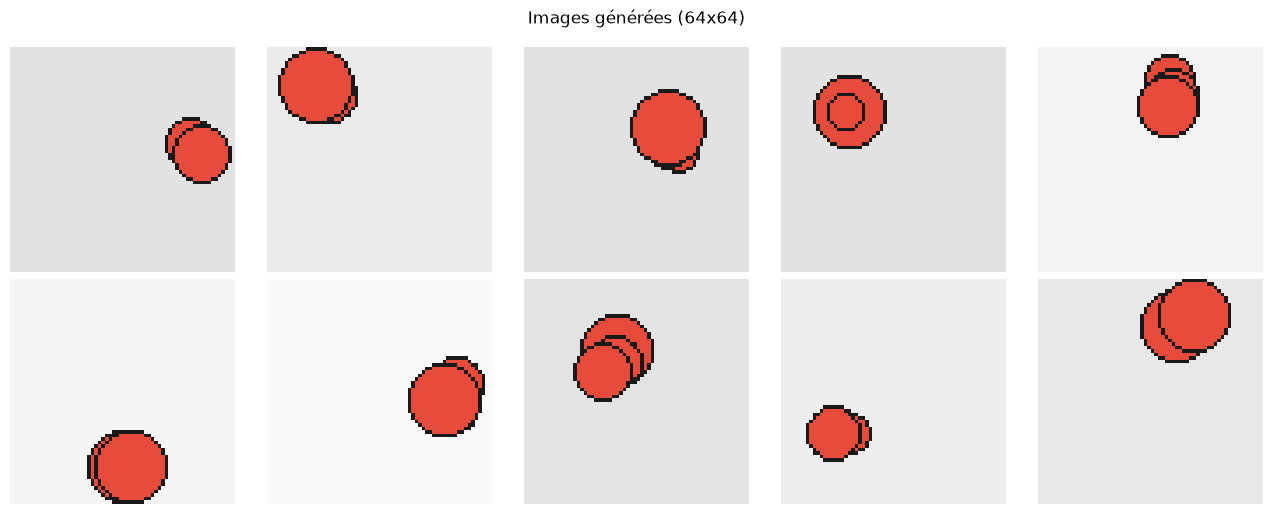

In [ ]:
rng = random.Random(123)

# On demande entre 2 et 4 objets pour illustrer la limite des superpositions
pil_images = [make_example(MODEL_SIZE, "circle", rng, min_objects=2, max_objects=4)[0] for _ in range(10)]
show_images(pil_images, f"Images générées ({MODEL_SIZE}x{MODEL_SIZE})")

Les images sont déjà générées à la taille attendue par le détecteur (`MODEL_SIZE`×`MODEL_SIZE`, multiple du stride) : aucun redimensionnement, on les convertit simplement en tenseurs `(3, H, W)` normalisés dans [0, 1].

In [ ]:
def to_tensor(image):
    return torch.from_numpy(np.asarray(image.convert("RGB"), dtype=np.float32).copy()).permute(2, 0, 1) / 255.0

def parse_labels(label):
    """Sépare le texte brut pour récupérer les coordonnées de TOUS les cercles."""
    return [tuple(map(float, line.split())) for line in label.splitlines()]

def make_dataset(count, seed, anchors):
    rng = random.Random(seed)
    dataset_images, targets = [], []
    for _ in range(count):
        image, label = make_example(MODEL_SIZE, "circle", rng, 2, 4)
        dataset_images.append(to_tensor(image))
        # On envoie la liste des cercles à notre fonction code()
        targets.append(code(parse_labels(label), size=MODEL_SIZE, anchors=anchors))
        
    return TensorDataset(torch.stack(dataset_images), torch.stack(targets))

# Petit test pour s'assurer que notre tenseur a bien gonflé à 15 canaux
dummy_dataset = make_dataset(count=2, seed=42, anchors=ANCHORS)
print("Dimension des images :", dummy_dataset[0][0].shape)
print("Dimension des cibles (K*5) :", dummy_dataset[0][1].shape)

torch.Size([10, 3, 64, 64])


## 2. Génération d'un jeu de données d'entraînement plus grand
On génère 2 000 images pour l'entraînement et 400 images indépendantes pour la validation. Les étiquettes (en pixels) sont encodées en cibles `(5, G, G)`.

## 3. Entraînement du modèle


In [ ]:
TRAIN_SAMPLES = 2000
VAL_SAMPLES = 400
BATCH_SIZE = 64
EPOCHS = 50
LR = 3e-3

import tempfile
import matplotlib.pyplot as plt
from datetime import datetime
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

LOG_ROOT = Path(tempfile.gettempdir()) / "tb_runs" / "demo"
LOG_ROOT.mkdir(parents=True, exist_ok=True)

def fit(name, anchors):
    torch.manual_seed(0)
    train_loader = DataLoader(make_dataset(TRAIN_SAMPLES, seed=7, anchors=anchors), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(make_dataset(VAL_SAMPLES, seed=8, anchors=anchors), batch_size=BATCH_SIZE)

    model = Detector(anchors)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"loss": [], "mean_iou": [], "recall": [], "precision": []}
    
    # Mode silencieux pour ne pas spammer le notebook, on affiche juste la fin
    for epoch in range(1, EPOCHS + 1):
        mean_loss = train(model, train_loader, optimizer)
        m = evaluate(model, val_loader, MODEL_SIZE)
        for key, value in (("loss", mean_loss), ("mean_iou", m["mean_iou"]),
                           ("recall", m["recall"]), ("precision", m["precision"])):
            history[key].append(value)
            
    print(f"[{name}] Fin! Rappel: {m['recall']:.0%} | Précision: {m['precision']:.0%}")
    model.eval()
    return model, history

print("1/2 : Entraînement du modèle de base (K=1)...")
model_base, history_base = fit("initial_K1", BASELINE_ANCHORS)

print("2/2 : Entraînement du modèle Option A (K=3)...")
model_k3, history_k3 = fit("ancres_K3", ANCHORS)

# On trace nos courbes comparatives !
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, key, title in zip(axes, ("loss", "mean_iou", "recall", "precision"),
                          ("Perte (train)", "IoU moyen (val)", "Rappel (val)", "Précision (val)")):
    ax.plot(history_k3[key], label="3 ancres (Option A)")
    ax.plot(history_base[key], label="initial (K=1)")
    ax.set_title(title); ax.set_xlabel("époque")
axes[0].legend()
fig.tight_layout(); plt.show()

Logs TensorBoard : C:\Users\UTILIS~1\AppData\Local\Temp\tb_runs\demo
epoch  1  loss 0.0447  val IoU 0.149  IoU>0.5 0%
epoch  2  loss 0.0269  val IoU 0.109  IoU>0.5 0%
epoch  3  loss 0.0222  val IoU 0.000  IoU>0.5 0%
epoch  4  loss 0.0203  val IoU 0.006  IoU>0.5 0%
epoch  5  loss 0.0191  val IoU 0.260  IoU>0.5 3%
epoch  6  loss 0.0176  val IoU 0.333  IoU>0.5 5%
epoch  7  loss 0.0170  val IoU 0.364  IoU>0.5 10%
epoch  8  loss 0.0147  val IoU 0.368  IoU>0.5 17%
epoch  9  loss 0.0149  val IoU 0.406  IoU>0.5 32%
epoch 10  loss 0.0130  val IoU 0.438  IoU>0.5 47%
epoch 11  loss 0.0122  val IoU 0.445  IoU>0.5 50%
epoch 12  loss 0.0120  val IoU 0.441  IoU>0.5 47%
epoch 13  loss 0.0109  val IoU 0.459  IoU>0.5 57%
epoch 14  loss 0.0102  val IoU 0.478  IoU>0.5 60%
epoch 15  loss 0.0101  val IoU 0.480  IoU>0.5 55%
epoch 16  loss 0.0089  val IoU 0.465  IoU>0.5 52%
epoch 17  loss 0.0089  val IoU 0.486  IoU>0.5 52%
epoch 18  loss 0.0083  val IoU 0.461  IoU>0.5 47%
epoch 19  loss 0.0082  val IoU 0.458 

In [6]:
# Affiche la commande à lancer dans un terminal pour ouvrir TensorBoard dans le navigateur
import sys
print(f'& "{sys.executable}" -m tensorboard.main --logdir "{LOG_ROOT}" --port 6006')
print("Puis ouvrir http://localhost:6006")

& "c:\Users\Utilisateur\Downloads\sujet_tensorboard (1)\.venv\Scripts\python.exe" -m tensorboard.main --logdir "C:\Users\UTILIS~1\AppData\Local\Temp\tb_runs\demo" --port 6006
Puis ouvrir http://localhost:6006


## 4. Feature maps

torch.Size([10, 32, 8, 8])


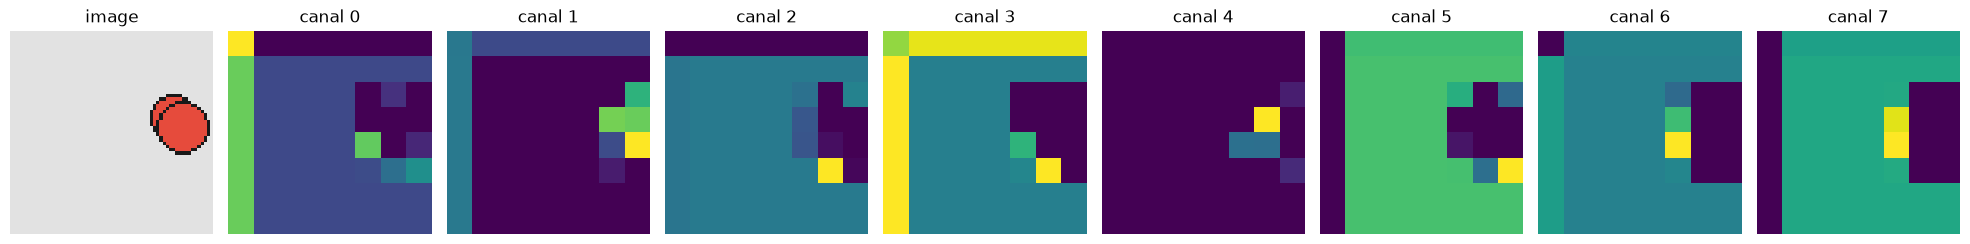

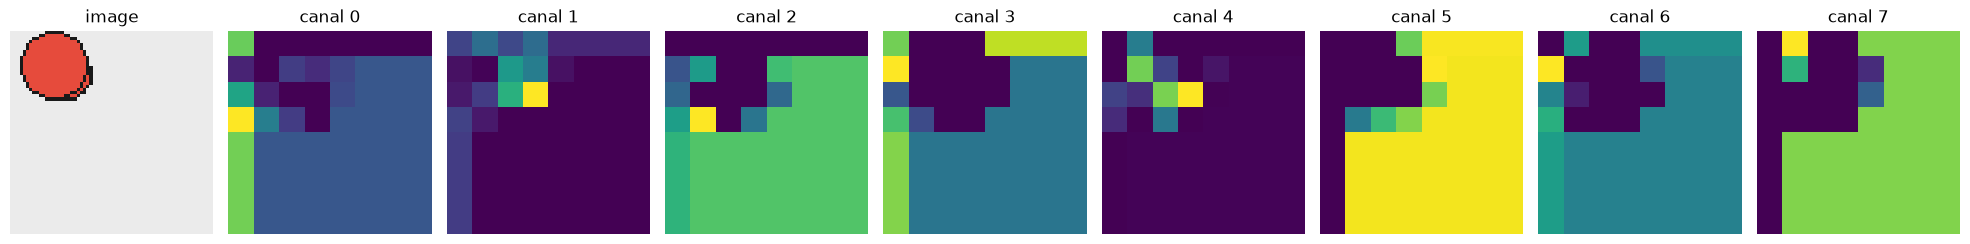

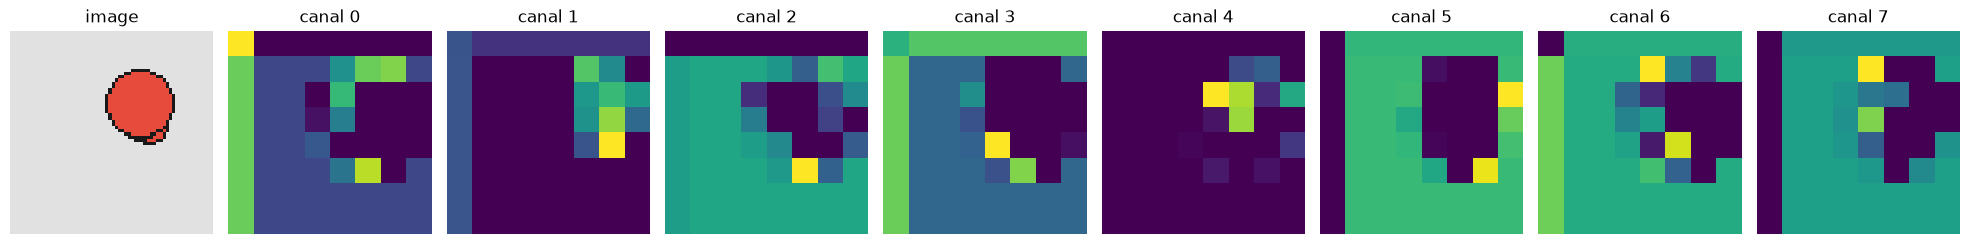

tensor([[ 0.1129,  0.2516, -0.1372],
        [-0.0473, -0.0708, -0.0601],
        [-0.2373,  0.0510, -0.1030]], grad_fn=<SelectBackward0>)


In [ ]:
images = torch.stack([to_tensor(im) for im in pil_images])

with torch.no_grad():
    maps = model_k3.feature_maps(images)   # Sortie : (N, 32, 8, 8)

print("Dimension des feature maps :", maps.shape)

# On affiche les 8 premiers canaux de la feature map pour 3 images
for i in range(3):
    show_feature_maps(images[i], maps[i], n_maps=8)

## 5. Prédiction, décodage et NMS : une boîte par image

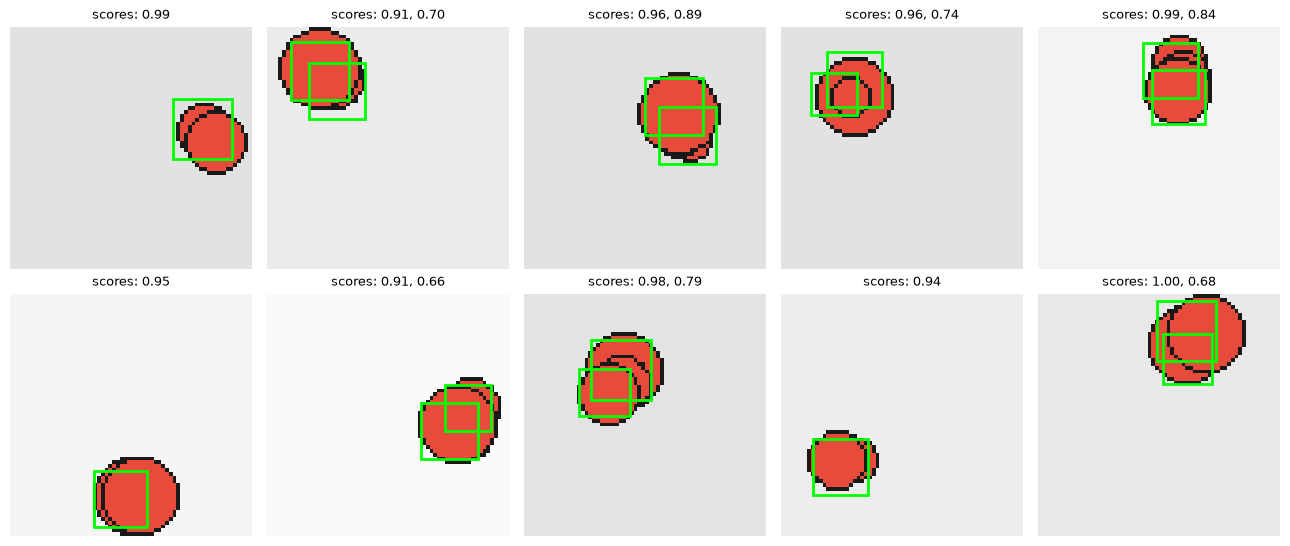

In [ ]:
with torch.no_grad():
    logits = model_k3(images)

# Application du seuil de confiance (0.7) et du NMS corrigé (0.7) pour tolérer les collisions
results = [predict(l, MODEL_SIZE, model_k3.anchors, score_threshold=0.70, iou_threshold=0.7) for l in logits]

# On dessine !
show_detections(list(images), [b for b, _ in results], [s for _, s in results])